# Phase 3 — Feature extraction and dataset preparation

We turn each row (one segment) into a small vector of interpretable features and keep its label. Which features are allowed depends on the
Phase 1 verdict:

| Phase 1 verdict | Features computed |
|---|---|
| `blocks` / `single_sequence` | amplitude statistics + temporal features + spectral features, **separately for every block** |
| `unverified` | only order-independent statistics of the whole row (no spectral or temporal features) |

Frequency features use Welch PSD estimated **once per block** and reused for every spectral feature.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from eeg_signal_classification import data_loader as dl, feature_extraction as fe
from eeg_signal_classification.utils import FEATURE_FILE, PROCESSED_DIR, RESULTS_DIR, load_json, load_structure, save_json, set_seed

set_seed(); sns.set_theme(style="whitegrid"); FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
structure = load_structure(); FS_HZ = structure["fs_hz"]
MODE = fe.feature_mode(structure)
META_FILE = PROCESSED_DIR / "feature_meta.json"
config = {"layout": structure["layout"], "block_length": structure["block_length"], "n_blocks": structure["n_blocks"], "fs_hz": FS_HZ, "mode": MODE}
print("feature mode:", MODE, "|", config)
if MODE == "statistical_only":
    print("WARNING: row structure unverified -> spectral/temporal features are NOT computed (they would be meaningless).")
signals, labels = dl.open_signals(), dl.load_labels()

feature mode: full | {'layout': 'blocks', 'block_length': 2048, 'n_blocks': 18, 'fs_hz': None, 'mode': 'full'}


## 1. Extract features (cached)

Rows are processed in chunks of 500 from the memory-mapped array, so RAM stays small. The result is cached in `data/processed/features.csv`
together with the configuration that produced it; if you change the layout or sampling-rate assumption the cache is rebuilt automatically.
Set `FORCE = True` to rebuild anyway.

In [2]:
FORCE = False
cached = FEATURE_FILE.exists() and META_FILE.exists() and load_json(META_FILE).get("config") == config
if cached and not FORCE:
    table = pd.read_csv(FEATURE_FILE); print("loaded cached feature table", table.shape)
else:
    table = fe.extract_feature_table(signals, labels, structure, FS_HZ, chunk_rows=500); print("extracted feature table", table.shape)
table.iloc[:5, :8]

extracted feature table (11233, 452)


,row_index,target,blk01_mean,blk02_mean,blk03_mean,blk04_mean,blk05_mean,blk06_mean
0,0,0,-0.015788,-0.002971,-0.005938,0.008552,-0.018734,-0.001850
1,1,0,-0.010850,-0.005357,-0.004972,-0.002038,-0.020221,-0.004588
2,2,0,-0.002880,0.006855,-0.008955,0.000812,0.006957,0.002783
3,3,0,0.101844,0.006996,-0.009426,0.003950,0.077744,0.012447
4,4,0,0.027645,-0.002155,-0.018785,-0.008238,0.019650,0.000799


## 2. Quality checks

We check for missing values, infinite values and constant features (a constant feature carries no information). Constant features are removed
and listed; NaN or infinite values stop the notebook, because silently imputing them would hide a bug.

In [3]:
quality = fe.quality_report(table)
print({k: v if k != "constant_features" else f"{len(v)} features" for k, v in quality.items()})
if quality["n_nan"] or quality["n_inf"]:
    bad = table.drop(columns=["row_index", "target"]).replace([np.inf, -np.inf], np.nan).isna().sum()
    raise ValueError(f"NaN/inf found in features: {bad[bad > 0].to_dict()}")
assert (table["row_index"].to_numpy() == np.arange(len(table))).all() and (table["target"].to_numpy() == labels).all(), "labels misaligned"
print("labels aligned with rows: OK")
constant = quality["constant_features"]
table = table.drop(columns=constant)
print("removed constant features:", constant[:10], "..." if len(constant) > 10 else "")
print("final feature table:", table.shape)

{'n_rows': 11233, 'n_features': 450, 'n_nan': 0, 'n_inf': 0, 'constant_features': '0 features'}
labels aligned with rows: OK
removed constant features: [] 
final feature table: (11233, 452)


## 3. Save the feature table and documentation

In [4]:
table.to_csv(FEATURE_FILE, index=False)
save_json({"config": config, "n_features": table.shape[1] - 2, "removed_constant_features": constant,
           "label_column_meaning": {"seizure_label": structure["seizure_label"], "status": structure["label_status"]}}, META_FILE)
descriptions = fe.feature_descriptions(structure, FS_HZ)
descriptions.to_csv(RESULTS_DIR / "feature_descriptions.csv", index=False)
pd.set_option("display.max_colwidth", 120); display(descriptions)
print("saved:", FEATURE_FILE.name, "and feature_meta.json in", PROCESSED_DIR.name)

,feature,meaning,type
0,mean,Average value of the segment (offset).,statistical
1,std,Standard deviation: typical amplitude fluctuation.,statistical
2,var,Variance: signal power around the mean.,statistical
3,rms,Root mean square: overall amplitude including offset.,statistical
4,energy,Sum of squares: total signal energy of the segment.,statistical
5,ptp,"Peak-to-peak: max minus min, sensitive to large spikes.",statistical
6,skew,Skewness: asymmetry of the amplitude distribution.,statistical
7,kurtosis,Excess kurtosis: heavy tails / spikiness of the amplitude distribution.,statistical
8,line_length,Sum of |x[n+1]-x[n]|: grows with amplitude and with fast oscillation; classic seizure feature.,temporal
9,hjorth_mobility,Hjorth mobility: sqrt(var(dx)/var(x)); proxy for the mean frequency.,temporal


saved: features.csv and feature_meta.json in processed


### Feature names

`blkNN_<feature>` is the feature of block `NN` (blocks are contiguous segments of a row; they are **not** confirmed to be electrodes),
`seqNN_` the single sequence, `row_` a whole-row statistic. For spectral features in the normalised case, bands are `nb1`...`nb5`
and frequencies are in cycles/sample.

## 4. Which features separate the classes?

Effect size per feature: Cohen's d = (mean_seizure − mean_non-seizure) / pooled std. |d| ≈ 0.2 small, 0.5 medium, 0.8 large. This is a descriptive
screen on **all** rows and is not used to select features for the model (that would leak test information).

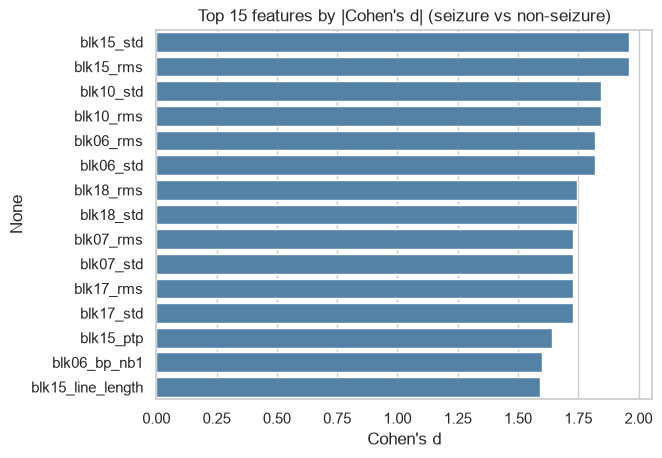

In [5]:
feats = table.drop(columns=["row_index", "target"])
is_seizure = (table["target"] == structure["seizure_label"]).to_numpy()
a, b = feats[is_seizure], feats[~is_seizure]
pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
effect = ((a.mean() - b.mean()) / pooled).rename("cohens_d").to_frame()
effect["abs_d"] = effect["cohens_d"].abs()
effect = effect.sort_values("abs_d", ascending=False)
effect.to_csv(RESULTS_DIR / "feature_effect_sizes.csv")
top = effect.head(15)
ax = sns.barplot(x=top["cohens_d"], y=top.index, color="steelblue")
ax.set(title="Top 15 features by |Cohen's d| (seizure vs non-seizure)", xlabel="Cohen's d")
plt.savefig(FIG / "03_effect_sizes.png", dpi=150, bbox_inches="tight"); plt.show()

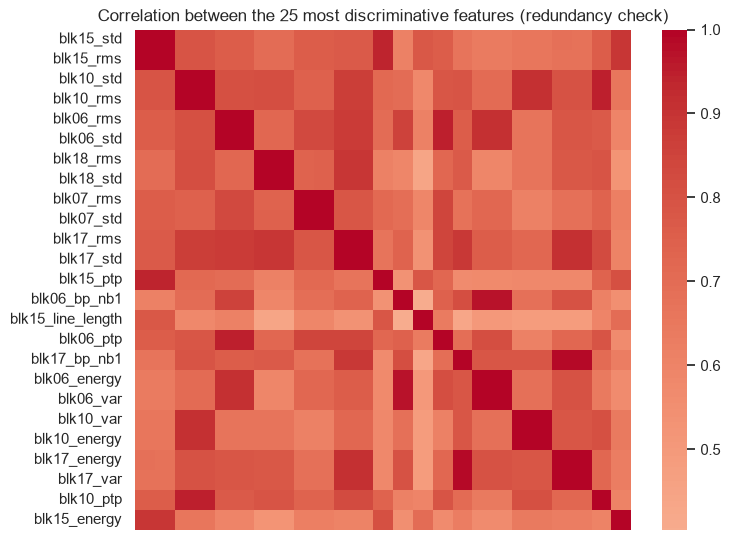

In [6]:
top_names = effect.index[:min(25, len(effect))]
plt.figure(figsize=(8, 6.5)); sns.heatmap(feats[top_names].corr(), cmap="coolwarm", center=0, xticklabels=False)
plt.title("Correlation between the 25 most discriminative features (redundancy check)")
plt.savefig(FIG / "03_feature_correlation.png", dpi=150, bbox_inches="tight"); plt.show()

Strongly correlated features (red blocks) carry overlapping information. Tree models handle this well; logistic regression and SVM
are affected less than you might expect because the features are standardised, but interpretation of single coefficients is unreliable.